# 03 - Preprocessing, Feature Engineering and Leakage

**Goal:** turn raw columns into model-ready numbers *without* letting information from validation/test customers influence training.

## Core idea: stateless vs stateful transformations
| Type | Example | Learns something from data? | Safe before the split? |
|---|---|---|---|
| **Stateless** (row-wise rule) | `num_addon_services = count of "Yes"`; `tenure_group` bins with fixed edges | No | Yes |
| **Stateful** (fitted) | `StandardScaler` (mean/std), median imputer, one-hot category list, feature selection, SMOTE | **Yes** | **No - fit on training data only** |

If a stateful step is fitted on all data, validation customers have already "voted" on the scaling, the categories, or the selected features, and your validation score is optimistic.
We prevent this by putting **everything** in one scikit-learn `Pipeline`; `cross_validate` then refits the whole pipeline inside each training fold.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets notebooks import the src/ package

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure into reports/figures (used by README and dashboard)."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

## 1. Engineered features (hypothesis-driven, kept deliberately few)
| Feature | Hypothesis |
|---|---|
| `num_addon_services` | customers using more add-ons are more embedded and less likely to leave |
| `is_autopay` | automatic payment removes a monthly "decision point" (electronic-check payers churn most in EDA) |
| `tenure_group` | churn vs tenure is non-linear; bins let a *linear* model represent that. Trees can find such splits alone. |

We will test whether they actually help instead of assuming it.

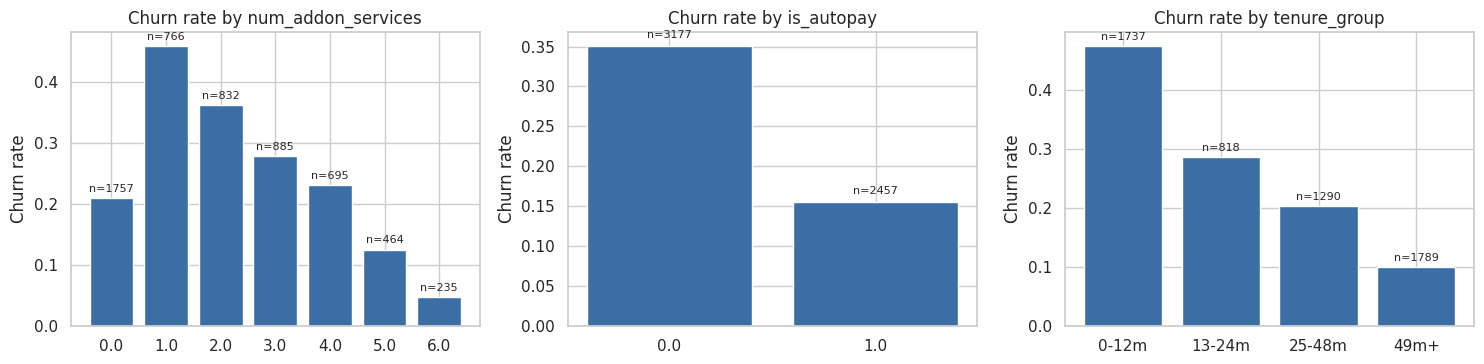

In [2]:
from src.data_preprocessing import load_split, split_xy, make_pipeline, build_preprocessor
from src.feature_engineering import add_engineered_features
train = load_split("train"); X, y = split_xy(train)
fe = add_engineered_features(X).assign(Churn=y)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["num_addon_services", "is_autopay", "tenure_group"]):
    g = fe.groupby(col)["Churn"].agg(["mean", "size"]).reset_index()
    if col == "tenure_group": g[col] = pd.Categorical(g[col], ["0-12m", "13-24m", "25-48m", "49m+"], ordered=True); g = g.sort_values(col)
    ax.bar(g[col].astype(str), g["mean"], color="#3b6ea5"); ax.set(title=f"Churn rate by {col}", ylabel="Churn rate")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): ax.text(i, m + 0.01, f"n={n}", ha="center", fontsize=8)
plt.tight_layout(); savefig("fe_engineered_feature_churn_rates.png")

## 2. The preprocessing pipeline
* **Numeric:** median imputation (safety net - there are no NaNs after cleaning, but new data might have them) -> scaling *only for Logistic Regression*.
  *Why scale for LR?* L2 regularisation penalises coefficient size; a feature measured in dollars (0-8,000) vs months (0-72) would otherwise be penalised unequally, and gradient-based solvers converge faster on comparable scales.
  *Why not for trees?* Splits compare a feature to a threshold; any monotone rescaling gives identical splits.
* **Categorical:** most-frequent imputation (safety net) -> **one-hot encoding** with `handle_unknown="ignore"` (an unseen category at prediction time becomes all zeros instead of crashing the app).
  *Why one-hot, not label encoding?* Label encoding invents an order (DSL=0 < Fiber=1 < None=2) that linear models would take literally.
* `customerID` is dropped automatically (`remainder="drop"`).

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn import set_config
set_config(display="text")
pipe = make_pipeline(LogisticRegression(max_iter=3000), "base", scale_numeric=True)
print(pipe)
pipe.fit(X, y)
names = pipe.named_steps["preprocess"].get_feature_names_out()
print(f"\n{X.shape[1]} raw features -> {len(names)} encoded features. First 6: {list(names[:6])}")

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_engineered_features at 0x7fe34b9768e0>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='mo...
                                                               

## 3. Why leakage matters - a demonstration you can reproduce
Classic experiment: generate **pure noise** features and a **random** target. A trustworthy evaluation must give ROC-AUC ~ 0.5 (no signal exists).
We compare two ways of doing "select the 20 best features, then fit a model":
* **Wrong:** pick the 20 features that correlate best with the target using *all* rows, *then* cross-validate.
* **Right:** put the selection step *inside* the pipeline so it is refitted on each training fold.

In [4]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
rng = np.random.default_rng(0)
Xn, yn = rng.normal(size=(300, 2000)), rng.integers(0, 2, 300)           # no relationship at all
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Xsel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)                 # leakage: target used on ALL rows
wrong = cross_val_score(LogisticRegression(max_iter=1000), Xsel, yn, cv=cv, scoring="roc_auc").mean()
right = cross_val_score(Pipeline([("sel", SelectKBest(f_classif, k=20)), ("lr", LogisticRegression(max_iter=1000))]), Xn, yn, cv=cv, scoring="roc_auc").mean()
print(f"Selection outside CV (leaky):  ROC-AUC = {wrong:.3f}   <- looks like real skill, but the data is pure noise")
print(f"Selection inside pipeline:     ROC-AUC = {right:.3f}   <- honest: no signal, so ~0.5")

Selection outside CV (leaky):  ROC-AUC = 0.809   <- looks like real skill, but the data is pure noise
Selection inside pipeline:     ROC-AUC = 0.504   <- honest: no signal, so ~0.5


The leaky number looks like a genuinely predictive model even though the target was random. Scaling and imputation leak much less, but the principle is identical - and it is the reason this project never fits a transformer outside a pipeline.

## 4. Do the engineered features actually help? (decided by cross-validation, not by intuition or the test set)
We compare the `base` and `engineered` feature sets on **identical folds** so the comparison is *paired*. The primary metric is PR-AUC (average precision).
**Decision principle:** prefer the simpler feature set unless the extra features give a gain that is both *consistent across folds* and *practically meaningful*.

In [5]:
from sklearn.model_selection import cross_validate
from src.train import get_model_specs, build_pipeline
specs = get_model_specs()
cv = StratifiedKFold(config.N_SPLITS, shuffle=True, random_state=config.RANDOM_STATE)
rows = []
for name in ["LogisticRegression", "XGBoost"]:
    scores = {fs: cross_validate(build_pipeline(name, fs, specs[name]), X, y, cv=cv, scoring="average_precision", n_jobs=-1)["test_score"] for fs in ["base", "engineered"]}
    d = scores["engineered"] - scores["base"]
    rows.append({"model": name, "AP base": scores["base"].mean(), "AP engineered": scores["engineered"].mean(),
                 "mean paired diff": d.mean(), "std of paired diff": d.std(ddof=1), "folds where engineered better": f"{(d > 0).sum()}/{len(d)}",
                 "fold-to-fold std of AP (base)": scores["base"].std(ddof=1)})
ablation = pd.DataFrame(rows); ablation.to_csv(config.REPORTS_DIR / "feature_set_ablation_paired.csv", index=False)
display(ablation.round(4))

,model,AP base,AP engineered,mean paired diff,std of paired diff,folds where engineered better,fold-to-fold std of AP (base)
0,LogisticRegression,0.6615,0.6651,0.0036,0.0069,3/5,0.0217
1,XGBoost,0.6674,0.6695,0.0021,0.0019,5/5,0.0218


**Reading the output.**
* Logistic Regression: the engineered set is better by only +0.004 AP on average, wins in just 3 of 5 folds, and the paired difference is nearly twice its own mean (SD 0.007) - no reliable benefit.
* XGBoost: the gain is *consistent* (5 of 5 folds) but tiny: +0.002 AP, roughly a tenth of the fold-to-fold spread (SD 0.022) of the AP estimate itself.
* **Decision:** these gains are too small to matter in practice, so we keep the simpler `base` feature set (`DEFAULT_FEATURE_SET = "base"` in `src/train.py`).
  *Transparency note:* I made this call after a first ablation run on the development set (never the test set) and this paired re-run confirms the same picture. It is a judgement call - XGBoost's consistency is a reason to consider the engineered set if the numbers were larger. Re-run everything with `python -m src.train --feature-set engineered` to compare.
* A negative result is still a result: we tested three plausible hypotheses and found the models already capture that information from the raw columns.

## 5. Class imbalance: what we do and what we deliberately do *not* do
* Churn is ~26.5% of customers - **moderate** imbalance.
* **We do not use SMOTE / over-/under-sampling.** Reasons: (1) it must only ever be applied inside training folds, which is easy to get wrong; (2) synthetic one-hot rows are unrealistic; (3) **it distorts predicted probabilities**, and we want trustworthy *risk scores* for a cost-based threshold. Moving the decision threshold achieves the same trade-off between recall and precision without changing the data.
* Alternative: `class_weight="balanced"` re-weights errors. Let us see what it does to probability quality on this dataset.

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss, average_precision_score, precision_score, recall_score
res = []
for label, cw in [("unweighted", None), ("class_weight='balanced'", "balanced")]:
    p = cross_val_predict(make_pipeline(LogisticRegression(max_iter=3000, class_weight=cw), "base", True), X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    res.append({"logistic regression": label, "mean predicted probability": p.mean(), "actual churn rate": y.mean(),
                "PR-AUC": average_precision_score(y, p), "Brier (lower=better)": brier_score_loss(y, p),
                "precision @0.5": precision_score(y, p >= 0.5), "recall @0.5": recall_score(y, p >= 0.5)})
display(pd.DataFrame(res).round(3))

,logistic regression,mean predicted probability,actual churn rate,PR-AUC,Brier (lower=better),precision @0.5,recall @0.5
0,unweighted,0.266,0.265,0.658,0.135,0.652,0.544
1,class_weight='balanced',0.414,0.265,0.657,0.165,0.517,0.801


**What to notice:** re-weighting leaves the *ranking* quality (PR-AUC) essentially unchanged, but it shifts probabilities upward (mean predicted probability far above the true churn rate) and worsens the Brier score - the scores stop meaning "probability of churn".
It raises recall at 0.5 only because it moves customers across the threshold, which a lower threshold on the unweighted model does too.
**Decision:** train unweighted models and handle the precision/recall trade-off through an explicitly chosen threshold. (Class weights remain a valid tool when you only need a ranking or a hard label and do not care about calibrated probabilities.)

## What to remember / interview questions
* *"Why must preprocessing be fitted only on training data?"* - Otherwise validation data influences the transformation, giving over-optimistic estimates.
* *"One-hot vs label encoding?"* - One-hot avoids implying an order; trees can tolerate label encoding, linear models cannot.
* *"When would you use SMOTE and what is the pitfall?"* - Severe imbalance, and only inside training folds (imblearn pipeline). Pitfalls: leakage if applied before splitting, unrealistic synthetic points, miscalibrated probabilities.
* *"You added features and CV improved by 0.002. Do you keep them?"* - Compare to fold-to-fold noise; prefer the simpler model unless the gain is consistent.